In [31]:
from feos import *
import feos
from feos import EquationOfState, Parameters, PhaseDiagram, PhaseEquilibrium
import si_units as si
import numpy as np
import pandas as pd
from si_units import *
import matplotlib.pyplot as plt
from scipy.optimize import *
import seaborn as sns
sns.set_context('poster')
sns.set_palette('Dark2')
sns.set_style('ticks')
colors = sns.palettes.color_palette('Dark2', 8)

In [32]:
tc = 5.1953
rho_c = 17.4 * MOL / LITER * 4.002602 * GRAM /MOL / (KILOGRAM/METER**3)
vle = pd.read_csv("data/helium_data/nist_vle.txt", sep="\t")
#vle = vle[vle['Temperature (K)'] < 0.9 * tc]
isotherms = pd.read_csv("data/helium_data/nist_isotherms.txt", sep="\t")
#isotherms = isotherms.iloc[::2]

In [33]:
#ailo = dict(sigma=2.7443, epsilon_k=5.4195, rep=9, att=6, c_sigma=[1.0]*3, c_epsilon_k=[1.0]*3, c_rep=[1.0]*5)
vrqmie_ailo = dict(m=1.0, sigma=2.7443, epsilon_k=5.4195, lr=9, la=6, fh=1)
sina = dict(m=1.0,  sigma=2.674056, epsilon_k=9.466831, lr=11.981772, la=6, fh=1) #c_sigma=c_sigma,  c_epsilon_k=c_epsilon_k, c_lr=c_lr)
vrq_pr = PureRecord(identifier=Identifier("helium"), molarweight=4.002602, **vrqmie_ailo)
vrq_model = EquationOfState.saftvrqmie(Parameters.new_pure(vrq_pr))

#vle_vrq = PhaseDiagram.pure(vrq_model, 2.5*KELVIN, 100)
df_vrq = PhaseDiagram.pure(vrq_model, min_temperature=2.5*si.KELVIN, npoints=250).to_dict(Contributions.Residual)
# Does not converge for temperatures below 2.7

# uv-CS with optimized parameters
thijs = dict(
    sigma=2.6953,
    epsilon_k=5.2850,
    rep=8.2761,
    att=6.0,
    c_sigma=[4.1529, 17.130, 4.6523],
    c_epsilon_k=[0.25290, 0.0, 0.42998],
    c_rep=[0.88165, 1.0523, 2.7524, 0.97560, 0.82524]
)
pr = PureRecord(identifier=Identifier("helium"), molarweight=4.002602, **thijs)
cs_model = EquationOfState.uvcstheory(Parameters.new_pure(pr))
df_cs = PhaseDiagram.pure(cs_model, min_temperature=2.5*si.KELVIN, npoints=250).to_dict(Contributions.Residual)

In [34]:
#df_vrq

In [35]:
def eos_from_parameter(pars):
    c_sigma=[pars[0], pars[1], pars[2]] #[0.7652,1.444,0.7686], 
    c_epsilon_k=[pars[3], pars[4], pars[5]] #[1.1293,-0.5168,1.1744],
    c_lr= [pars[6], pars[7], pars[8], pars[9], pars[10]] #[0.8719,1.2691,1.6244,1.4737,0.6102]

    
    
   # c_sigma=[pars[0], pars[1], 1] #[0.7652,1.444,0.7686], 
   # c_epsilon_k=[1, pars[4], 1] #[1.1293,-0.5168,1.1744],
    #c_lr= [1, pars[7], pars[8], 1, pars[10]] #[0.8719,1.2691,1.6244,1.4737,0.6102]

    
    
    
    ailo = dict(m=1.0,  sigma=2.7443, epsilon_k=5.4195, lr=9, la=6, c_sigma=c_sigma,  c_epsilon_k=c_epsilon_k, c_lr=c_lr)
    sina = dict(m=1.0,  sigma=2.674056, epsilon_k=9.466831, lr=11.981772, la=6, c_sigma=c_sigma,  c_epsilon_k=c_epsilon_k, c_lr=c_lr)
    #,
    #        c_sigma=[0.7652,1.444,0.7686], 
    #        c_epsilon_k=[1.1293,-0.5168,1.1744],
    #        c_lr=[0.8719,1.2691,1.6244,1.4737,0.6102])

    vrcs_pr = feos.PureRecord(identifier=feos.Identifier("helium"), molarweight=4.002602, **ailo)
    vrcs_model = EquationOfState.saftvrcs_mie(Parameters.new_pure(vrcs_pr))

    return vrcs_model


def cost(pars):
    fit_dat = vle.loc[vle['Temperature (K)'] > 2.7 ]
    fit_dat = fit_dat.loc[fit_dat['Temperature (K)'] < 0.9 * tc]
    eos = eos_from_parameter(pars)
    error_rhol = []
    error_rhov = []
    error_ps = []
    err_rho = []
    n = len(vle)
    for i, row in fit_dat.iterrows():
        temp = row['Temperature (K)']
        try:
            feos_vle = PhaseEquilibrium.pure(eos, temperature_or_pressure=temp * KELVIN )
            #print(row['Temperature (K)'])
            rho_l = row["Density (l, kg/m3)"]
            rho_l_feos = feos_vle.liquid.mass_density() / KILOGRAM * METER**3

            error_rhol.append(2*(rho_l_feos- rho_l)/rho_l/ n)


            rho_v = row["Density (v, kg/m3)"]
            rho_v_feos = feos_vle.vapor.mass_density() / KILOGRAM * METER**3
            error_rhov.append((rho_v_feos- rho_v)/rho_v/n)

            pexp = row['Pressure (MPa)']
            pfeos = feos_vle.vapor.pressure() / (MEGA*PASCAL)
            error_ps.append((pfeos-pexp)/pexp/ n)
        except:
            
            error_rhol.append(3)
            error_rhov.append(3)
            error_ps.append(3)
                
        #print(pfeos)
        
    n = len(isotherms)
    for i, row in isotherms.iterrows():
        p_exp = row['Pressure (MPa)']
        t_exp = row['Temperature (K)']
        rho_exp = row['Density (l, kg/m3)']
        s = State(eos, temperature=t_exp * KELVIN, pressure=p_exp* MEGA*PASCAL)
        rho_feos = s.mass_density() / (KILOGRAM/METER**3)
        #Density (l, kg/m3)
        #print(rho_feos)
        err_rho.append((rho_feos- rho_exp)/rho_exp/ n)
        
    return np.concat([error_rhol , error_rhov, error_ps, err_rho])


#cost(par0)

par0 = 11 * [1]

#par0 = np.array([3.73411745e-01, 3.57533863e-08, 3.18153451e-01, 4.09018402e-08,
#       4.13360092e-08, 1.03241952e-01, 1.85681804e+00, 2.54645826e+00,
#       7.64416650e+00, 2.09394642e+00, 1.78768009e-07])


popt = least_squares(cost, par0) #, bounds=(0, 5000))

In [36]:
cost(popt.x)

array([ 5.70704384e-05,  4.02342830e-05,  1.78314908e-05,  2.27123564e-06,
       -9.70861485e-06, -1.89392931e-05, -2.38161729e-05, -2.49454615e-05,
       -2.51968882e-05, -2.27155857e-05, -2.02791440e-05, -1.59302843e-05,
       -1.00218471e-05, -5.27115308e-06,  3.71959932e-07,  4.19238733e-06,
        1.06912882e-05,  1.47364600e-05,  1.84242023e-05,  2.14321844e-05,
        2.34225396e-05,  2.65185814e-05,  2.53862468e-05,  2.45878061e-05,
        2.11884185e-05,  1.97701698e-05,  1.22060872e-05,  5.55179057e-06,
       -3.37230996e-06, -1.26826424e-05, -2.57809597e-05, -4.09717780e-05,
       -5.66267162e-05, -7.65934118e-05, -9.95940134e-05, -1.24524469e-04,
       -1.50508900e-04, -1.79772871e-04, -2.12240872e-04, -8.73602442e-05,
       -7.44123911e-05, -5.76466081e-05, -5.22876992e-05, -5.45418373e-05,
       -6.12134145e-05, -7.06494902e-05, -8.09887284e-05, -9.14895684e-05,
       -1.01047532e-04, -1.09404399e-04, -1.16653312e-04, -1.22395416e-04,
       -1.26787612e-04, -

In [37]:

#cost(par0)

In [42]:
popt.x

array([ 0.65815942,  2.78627824,  0.67327893, -0.60379248,  1.05699181,
       -0.09767145, -0.22569271,  0.28693996, -1.18113083, -0.3027373 ,
        0.52498658])

In [43]:
par0 = 11 * [1]
eos = eos_from_parameter(par0)
df_vrcs = PhaseDiagram.pure(eos, min_temperature=2.5*si.KELVIN, npoints=250).to_dict(feos.Contributions.Residual)


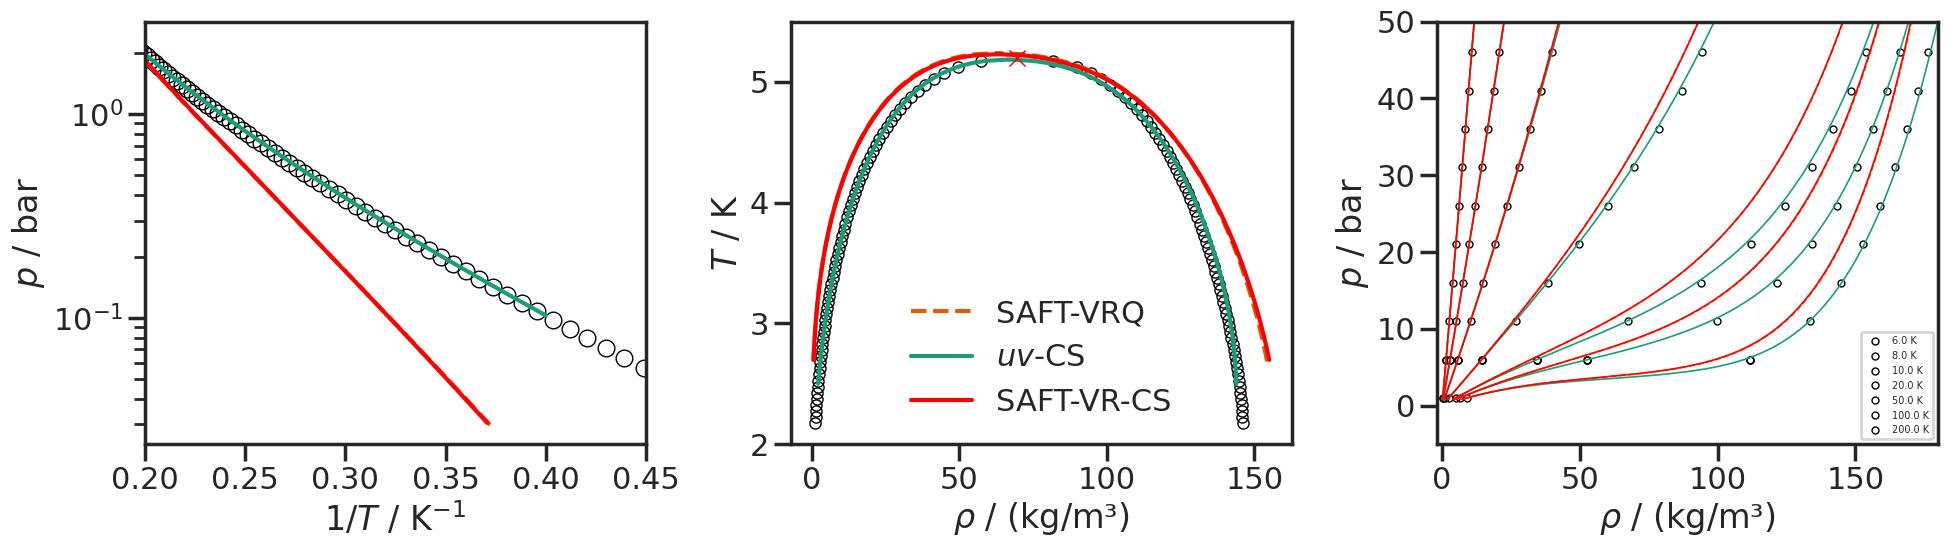

In [44]:
tc = 5.1953
rho_c = 17.4 * MOL / LITER * 4.002602 * GRAM /MOL / (KILOGRAM/METER**3)
vle = pd.read_csv("data/helium_data/nist_vle.txt", sep="\t")
#vle = vle[vle['Temperature (K)'] < 0.9 * tc][11:]
isotherms = pd.read_csv("data/helium_data/nist_isotherms.txt", sep="\t")


fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- Subplot 1: Vapor pressure vs Temperature  ---
axes[0].plot(1/ vle['Temperature (K)'], vle['Pressure (MPa)'] * (MEGA*PASCAL/BAR), 'o', mec='k', mfc='None')
axes[0].set_xlabel('$1/T$ / K$^{-1}$')
axes[0].set_ylabel('$p$ / bar')
#axes[0].set_title('Vapor Pressure')
axes[0].set_yscale('log')
axes[0].plot(1/np.array(df_vrq["temperature"]), np.array(df_vrq["pressure"]) * (PASCAL/BAR), '--', color=colors[1])
axes[0].plot(1/np.array(df_cs["temperature"]), np.array(df_cs["pressure"]) * (PASCAL/BAR),  color=colors[0])

axes[0].plot(1/np.array(df_vrcs["temperature"]), np.array(df_vrcs["pressure"]) * (PASCAL/BAR), 'r')#, color=colors[2])

axes[0].set_xlim(0.2, 0.45)

# --- Subplot 2: Density vs Temperature---
axes[1].plot(vle["Density (l, kg/m3)"], vle['Temperature (K)'], "o", mec='k', mfc='None', ms=8)#, ms=5)
axes[1].plot(vle["Density (v, kg/m3)"], vle['Temperature (K)'], "o", mec='k', mfc='None', ms=8)
axes[1].set_xlabel('$\\rho$ / (kg/m³)')
axes[1].set_ylabel('$T$ / K')
axes[1].set_ylim(2., 5.5)
axes[1].plot(df_vrq["mass density liquid"], df_vrq["temperature"],'--', color=colors[1], label="SAFT-VRQ")
axes[1].plot(df_vrq["mass density vapor"], df_vrq["temperature"], '--', color=colors[1] )


axes[1].plot(df_cs["mass density liquid"], df_cs["temperature"],'-', color=colors[0], label="$uv$-CS")
axes[1].plot(df_cs["mass density vapor"], df_cs["temperature"], '-', color=colors[0] )


axes[1].plot(df_vrcs["mass density liquid"], df_vrcs["temperature"],'-', color='r', label="SAFT-VR-CS")
axes[1].plot(df_vrcs["mass density vapor"], df_vrcs["temperature"], '-', color='r')#colors[2] )


axes[1].legend(loc='best', frameon=False)

#axes[1].set_title('VLE Envelope')

# --- Subplot 3: Pressure vs Density (isotherms) ---
for temp, group in isotherms.groupby('Temperature (K)'):
    axes[2].plot(group['Density (l, kg/m3)'],np.array( group['Pressure (MPa)']) * (MEGA*PASCAL)/BAR,
                 'o', mec='k', mfc='None', ms=5, label=f'{temp} K')
axes[2].set_xlabel('$\\rho$ / (kg/m³)')
axes[2].set_ylabel('$p$ / bar')
axes[2].legend(fontsize=7, loc='best')
axes[2].set_ylim(-5,50)
axes[2].set_xlim(-2, 180)


# --- Add theory isotherms ---
isotherm_temps = isotherms['Temperature (K)'].unique()

for i, temp in enumerate(sorted(isotherm_temps)):
    color = colors[i % len(colors)]  # cycle through your color list

    rho_min = isotherms[isotherms['Temperature (K)'] == temp]['Density (l, kg/m3)'].min()
    rho_max = isotherms[isotherms['Temperature (K)'] == temp]['Density (l, kg/m3)'].max()
    densities = np.linspace(rho_min * 0.8, rho_max * 1.2, 200)

    pressures = []
    valid_densities = []
    pressures_vrq = []
    pressures_vrcs = []
    for rho in densities:
        try:
            state = feos.State(
                cs_model,
                temperature=temp * si.KELVIN,
                density=(rho / 4.002602) * si.MOL / si.METER**3 * 1000  # kg/m³ → mol/m³
            )
            p = state.pressure(feos.Contributions.Residual) / BAR
            pig = (rho / 4.002602) * si.MOL / si.METER**3 * 1000 * RGAS * temp * KELVIN
            #print(pig / BAR)
            pressures.append(p + pig/BAR)
            
            
            state = feos.State(
                vrq_model,
                temperature=temp * si.KELVIN,
                density=(rho / 4.002602) * si.MOL / si.METER**3 * 1000  # kg/m³ → mol/m³
            )
            p = state.pressure(feos.Contributions.Residual) / BAR
            pressures_vrq.append(p + pig/BAR)
            
        
            state = feos.State(
                eos,
                temperature=temp * si.KELVIN,
                density=(rho / 4.002602) * si.MOL / si.METER**3 * 1000  # kg/m³ → mol/m³
            )
            p = state.pressure() / BAR
            pressures_vrcs.append(p )
        

            

            
            valid_densities.append(rho)
        except Exception:
            continue

    if valid_densities:
        axes[2].plot(valid_densities, pressures, '-',lw=1.2, color=colors[0] )
        axes[2].plot(valid_densities, pressures_vrq, '--',lw=1.2, color=colors[1] )
        axes[2].plot(valid_densities, pressures_vrcs, '-',lw=1.2, color='r')#colors[2] )
        
        
axes[1].plot(rho_c, tc, 'rx')
plt.tight_layout()
plt.show()

In [155]:
pwd

'/mnt/c/Users/anja/Documents/RESEARCH/POSTDOC/feos_fork_anja/feos/examples/saftvrcs'

In [45]:
_C_LR = [
    [-1.0577620680e02, 2.7130516920e01, -7.9885048560e-02],
    [-2.2875719760e03, 5.1995559760e02, 8.2111050000e-01],
    [1.7306319200e03, -1.7476174200e02, 3.2561549200e01],
    [-9.0993639000e01, 2.2823545260e01, -2.8168749280e-02],
    [-1.4764571200e03, 4.3447760860e02, -1.1267359060e01],
]
_C_SIGMA = [
    31.60144413, 2.09612861, 0.20116118,
    50.80286701, -4.28014515, 0.20063555,
    25.11333946, 1.35310377, 0.20250069,
]
_C_EPSILON = [
    10.60837315, 1.58987996, 0.19807347,
    17.92633472, -19.76493004, 3.91514157,
    7.17199935, 6.45489122, 0.18773935,
]

def eff_lr_ratio(d_star, lr, c_scale=None):
    c_scale = c_scale if c_scale is not None else [1.0] * 5
    pref = [(_C_LR[i][0] + lr * (_C_LR[i][1] + lr * _C_LR[i][2])) * c_scale[i] for i in range(5)]
    num = d_star * (d_star * (d_star * pref[2] + pref[1]) + pref[0]) + 1.0
    den = d_star * (d_star * pref[4] + pref[3]) + 1.0
    return num / den

def eff_sigma(d_star, lr, c_scale=None):
    c_scale = c_scale if c_scale is not None else [1.0] * 3
    c0 = _C_SIGMA[0] + lr * (_C_SIGMA[1] + lr * _C_SIGMA[2])
    c1 = _C_SIGMA[3] + lr * (_C_SIGMA[4] + lr * _C_SIGMA[5])
    c2 = _C_SIGMA[6] + lr * (_C_SIGMA[7] + lr * _C_SIGMA[8])
    return (d_star * (d_star * c1 * c_scale[1] + c0 * c_scale[0]) + 1.0) / (d_star * c2 * c_scale[2] + 1.0)

def eff_epsilon_k(d_star, lr, c_scale=None):
    c_scale = c_scale if c_scale is not None else [1.0] * 3
    c0 = _C_EPSILON[0] + lr * (_C_EPSILON[1] + lr * _C_EPSILON[2])
    c1 = _C_EPSILON[3] + lr * (_C_EPSILON[4] + lr * _C_EPSILON[5])
    c2 = _C_EPSILON[6] + lr * (_C_EPSILON[7] + lr * _C_EPSILON[8])
    return (d_star * (d_star * c1 * c_scale[1] + c0 * c_scale[0]) + 1.0) / (d_star * c2 * c_scale[2] + 1.0)